Add our import statements

In [1]:
%matplotlib inline
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler , MinMaxScaler
from sklearn.model_selection import train_test_split , GridSearchCV
from sklearn.metrics import accuracy_score , classification_report, confusion_matrix , roc_curve , auc
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from matplotlib import pyplot as plt
from matplotlib import rcParams
from sklearn.tree import plot_tree


Load the dataset


In [2]:
import os
if os.path.exists('heart.csv'):
    df = pd.read_csv('heart.csv')
else:
    url = 'https://raw.githubusercontent.com/Chakrios8/Heart_Disease_Prediction/refs/heads/main/heart.csv'
    df = pd.read_csv(url)

print(df.head(5))


   age  sex  cp  trestbps  chol  ...  oldpeak  slope  ca  thal  target
0   52    1   0       125   212  ...      1.0      2   2     3       0
1   53    1   0       140   203  ...      3.1      0   0     3       0
2   70    1   0       145   174  ...      2.6      0   0     3       0
3   61    1   0       148   203  ...      0.0      2   1     3       0
4   62    0   0       138   294  ...      1.9      1   3     2       0

[5 rows x 14 columns]


Summary of the Data

In [3]:
print('Dataframe Shape:' , df.shape)
print('Column Variables' , list(df.columns))

Dataframe Shape: (1025, 14)
Column Variables ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


Here is some more information on the attributes of each column in the dataset:

- **age** (continuous variable)
- **sex** (binary)
    - 1 = male
    - 0 = female
- **cp** : chest pain type
    - 1 = typical angina
    - 2 = atypical angina
    - 3 = non-anginal pain
    - 4 = asymptomatic)
- **trestbps** : resting blood pressure (continuous variable)
- **chol** : serum cholestoral in mg/dl (continuous variable)
- **fbs** : fasting blood sugar > 120 mg/dl
    - 1 = true
    - 0 = false
- **restecg** _ resting electrocardiographic results
    - 0 = normal
    - 1 = having ST-T wave abnormality
    - 2 = showing probable or definite left ventricular hypertrophy
- **thalach** : maximum heart rate achieved (continuous variable)
- **exang** : exercise induced angina
    - 1 = yes
    - 0 = no
- **oldpeak** : ST depression induced by exercise relative to rest (continuous variable)
- **slope** : the slope of the peak exercise ST segment
    - 1 = up-sloping
    - 2 = flat
    - 3 = down-sloping
- **ca** : number of major vessels
    - (0-3) colored by flourosopy
- **thal**
    - 0 = normal
    - 1 = fixed defect
    - 2 = reversable defect
- **target** : diagnosis of heart disease
    - 0 = no
    - 1 = yes

*more information on the data can be found: https://archive.ics.uci.edu/ml/datasets/heart+Disease*


In [4]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


## Data Visualizations

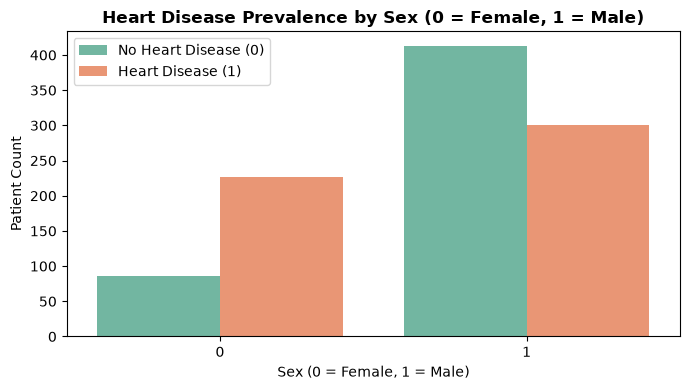

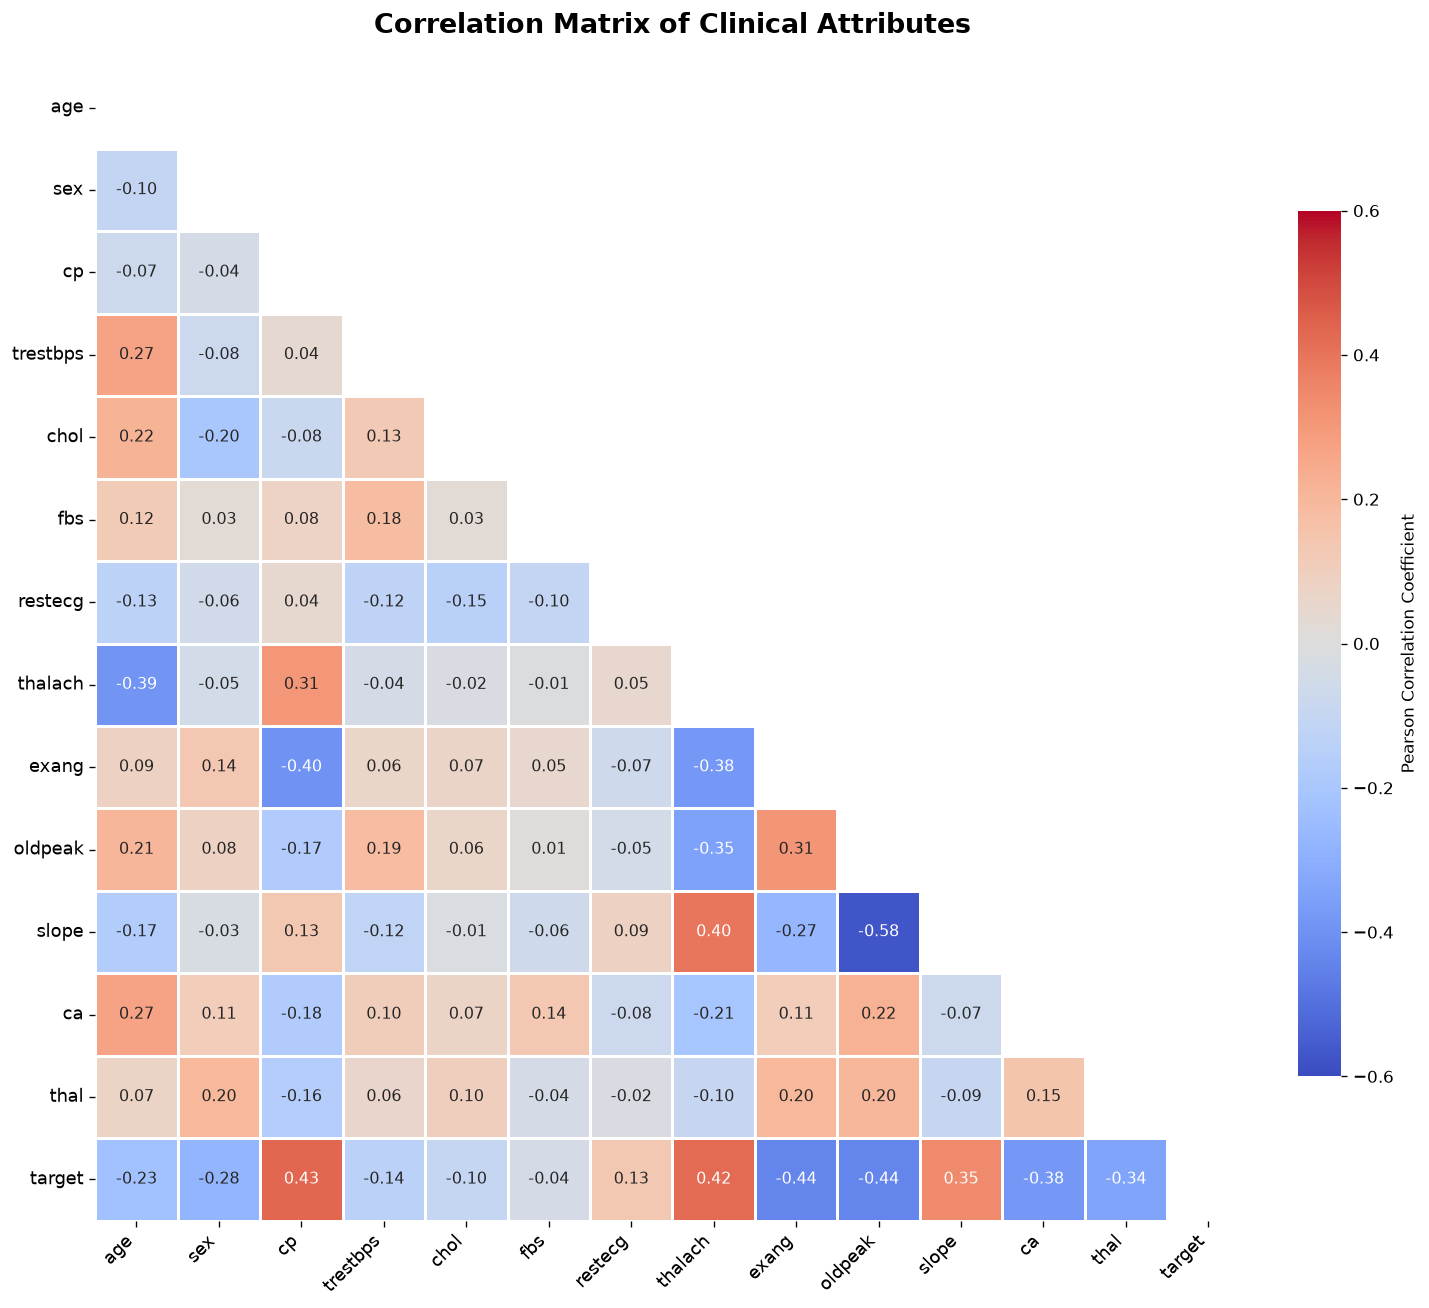

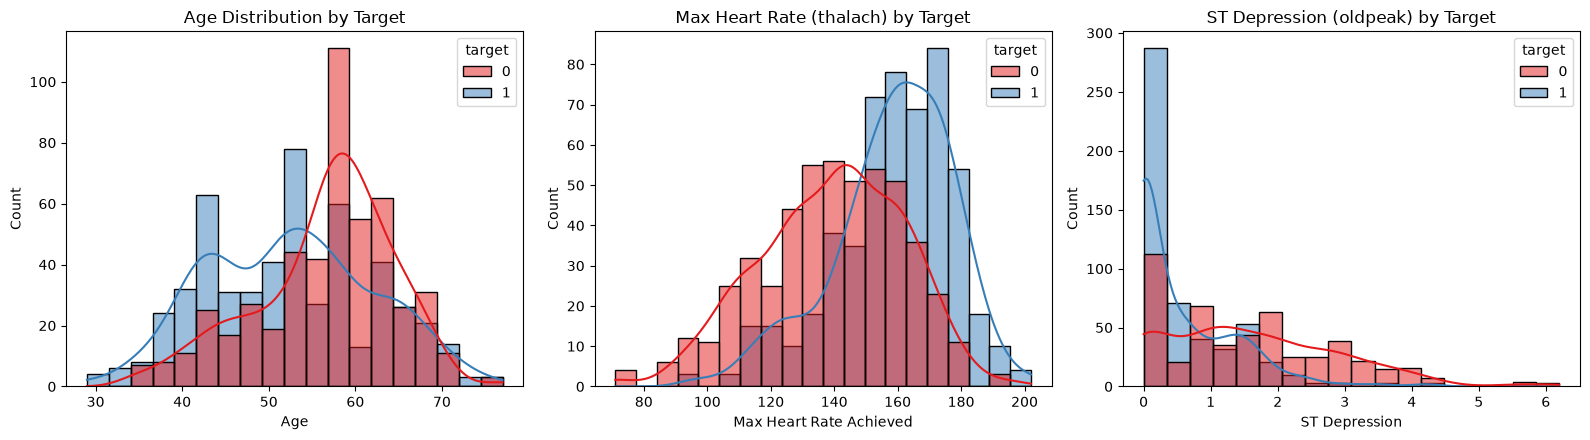

In [5]:
# 1. Distribution of Heart Disease by Sex
plt.figure(figsize=(7, 4))
sns.countplot(x='sex', hue='target', data=df, palette='Set2')
plt.title('Heart Disease Prevalence by Sex (0 = Female, 1 = Male)', fontsize=12, fontweight='bold')
plt.xlabel('Sex (0 = Female, 1 = Male)')
plt.ylabel('Patient Count')
plt.legend(['No Heart Disease (0)', 'Heart Disease (1)'])
plt.tight_layout()
plt.show()

# 2. Correlation Matrix Heatmap (Spacious & Formatted)
plt.figure(figsize=(14, 11), dpi=120)
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-0.6,
    vmax=0.6,
    center=0,
    square=True,
    linewidths=1.5,
    linecolor='white',
    cbar_kws={'shrink': 0.75, 'label': 'Pearson Correlation Coefficient', 'pad': 0.03},
    annot_kws={'size': 9.5}
)
plt.title('Correlation Matrix of Clinical Attributes', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(rotation=0, fontsize=11)
plt.tight_layout()
plt.show()

# 3. Distribution Analysis of Key Clinical Variables
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(data=df, x='age', hue='target', kde=True, ax=axes[0], palette='Set1')
axes[0].set_title('Age Distribution by Target')
axes[0].set_xlabel('Age')

sns.histplot(data=df, x='thalach', hue='target', kde=True, ax=axes[1], palette='Set1')
axes[1].set_title('Max Heart Rate (thalach) by Target')
axes[1].set_xlabel('Max Heart Rate Achieved')

sns.histplot(data=df, x='oldpeak', hue='target', kde=True, ax=axes[2], palette='Set1')
axes[2].set_title('ST Depression (oldpeak) by Target')
axes[2].set_xlabel('ST Depression')

plt.tight_layout()
plt.show()


## Data Pre-Processing Steps

Before feature scaling and dataset splitting, we check for duplicate patient records. In clinical datasets, duplicate entries can cause data leakage between the training and testing sets, leading to artificially inflated evaluation metrics. We drop duplicates programmatically to ensure robust generalizability.


In [6]:
# Check and remove duplicate records to prevent train-test data leakage
print(f"Initial raw patient records: {df.shape[0]}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Unique patient records after deduplication: {df.shape[0]}")

X = df.iloc[:,:13] # take the 1st 13 columns of the dataframe
y = df.iloc[: , -1] # take the last column of the dataframe

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


Initial raw patient records: 1025
Unique patient records after deduplication: 302


Split our dataset into testing and training samples to create our prediction algorithms

In [7]:
X_train,X_test,y_train,y_test = train_test_split(X_scaled,y,test_size=0.2 , random_state = 1234) # splitting the dataset into 80% validation and 20% test

##Logistic Regression

To start with, Im going to utilize the python package GridSearchCV to help me fine-tune the hyper-parameters of the logistic regression package. This will tell me which hyper-parameters I need to use to get the highest accuracy score on the machine learning model

In [8]:
parameters_lr = {
    'penalty' : [None , 'l2'],
    'C'       : [100 , 10 , 1.0 , 0.1 , 0.01],
    'solver'  : ['newton-cg' , 'lbfgs' , 'sag' , 'saga'],
    'max_iter' : [100]
}

cv = 5 # so this will split the dataset into 5 kfold validation chunks for the GridSearchCv to run through

lr = LogisticRegression(random_state = 1234)
clf = GridSearchCV(lr,
                   param_grid = parameters_lr,
                   scoring = 'accuracy',
                   cv = cv)

clf.fit(X_train , y_train)

print("Tuned Hyperparameters :", clf.best_params_)
print("Accuracy :", clf.best_score_)


Tuned Hyperparameters : {'C': 0.1, 'max_iter': 100, 'penalty': 'l2', 'solver': 'newton-cg'}
Accuracy : 0.8091836734693878


Based on the hyper-parameters found above, the best hyper-parameters I can use in my model are:

- penalty = l2
- C = 0.1
- solver = newton-cg

I will now plug those hyper-parameters into the model below for my analysis


In [9]:
lr = LogisticRegression(C = 0.1, penalty = 'l2', solver = 'newton-cg', max_iter = 100, verbose = 0, random_state = 1234)
lr.fit(X_train, y_train)
predict_lr = lr.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predict_lr))
print('Confusion Matrix:')
print(confusion_matrix(y_test, predict_lr))
print('Classification Report Table:')
print(classification_report(y_test, predict_lr))


Accuracy: 0.8852459016393442
Confusion Matrix:
[[25  4]
 [ 3 29]]
Classification Report Table:
              precision    recall  f1-score   support

           0       0.89      0.86      0.88        29
           1       0.88      0.91      0.89        32

    accuracy                           0.89        61
   macro avg       0.89      0.88      0.88        61
weighted avg       0.89      0.89      0.89        61



## Naive Bayes

Since there are fewer hyper-parameters for me to fine tune on the Gaussian Naive Bayes package, i am just going to run the package and pass through my training and test datasets to see what my accuracy score is with this method

In [10]:
gnb = GaussianNB()
gnb.fit(X_train , y_train)
predict_gnb = gnb.predict(X_test)

print("Accuracy:" , accuracy_score(y_test, predict_gnb))
print('Confusion Matrix:')
print(confusion_matrix(y_test, predict_gnb))
print('Classification Report Table:')
print(classification_report(y_test, predict_gnb))

Accuracy: 0.819672131147541
Confusion Matrix:
[[24  5]
 [ 6 26]]
Classification Report Table:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81        29
           1       0.84      0.81      0.83        32

    accuracy                           0.82        61
   macro avg       0.82      0.82      0.82        61
weighted avg       0.82      0.82      0.82        61



## K Nearest neighbors

In [11]:
parameters_knn = {
    'n_neighbors' : [1,3,5,7,9,11,13,15,17],
    'weights'       : ['uniform' , 'distance'],
    'metric'  : ['euclidean' , 'manhattan' , 'minkowski']
}

cv = 5

knn = KNeighborsClassifier()
knneighbors = GridSearchCV(knn,
                   param_grid = parameters_knn,
                   scoring = 'accuracy',
                   cv = cv)

knneighbors.fit(X_train , y_train)

print("Tuned Hyperparameters :", knneighbors.best_params_)
print("Accuracy :",knneighbors.best_score_)

Tuned Hyperparameters : {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'uniform'}
Accuracy : 0.8381802721088436


Based on the hyper-parameters found above, the best hyper-parameters I can use in my model are:

- n_neighbors = 5
- weights = uniform
- metric = manhattan

I will now plug those hyper-parameters into the model below for my analysis


In [12]:
knn = KNeighborsClassifier(n_neighbors = 5 , metric = 'manhattan' , weights = 'uniform')
knn.fit(X_train , y_train)
predict_knn = knn.predict(X_test)

print("Accuracy:" , accuracy_score(y_test, predict_knn))
print('Confusion Matrix:')
print(confusion_matrix(y_test, predict_knn))
print('Classification Report Table:')
print(classification_report(y_test, predict_knn))


Accuracy: 0.8032786885245902
Confusion Matrix:
[[23  6]
 [ 6 26]]
Classification Report Table:
              precision    recall  f1-score   support

           0       0.79      0.79      0.79        29
           1       0.81      0.81      0.81        32

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



## Decision Tree Classifier

In [13]:
parameters_dtree = {
    'criterion' : [ 'gini', 'entropy', 'log_loss' ],
    'splitter'  : ['best', 'random'],
    'max_leaf_nodes' : [10, 15, 20]
}

cv = 5 # 5-fold cross-validation

dtree = DecisionTreeClassifier(random_state = 1234)
dtc = GridSearchCV(dtree,
                   param_grid = parameters_dtree,
                   scoring = 'accuracy',
                   cv = cv)

dtc.fit(X_train , y_train)

print("Tuned Hyperparameters :", dtc.best_params_)
print("Accuracy :", dtc.best_score_)


Tuned Hyperparameters : {'criterion': 'entropy', 'max_leaf_nodes': 10, 'splitter': 'random'}
Accuracy : 0.7965986394557824


Based on the hyper-parameters found above, the best hyper-parameters to use in our model are:

- criterion = entropy
- splitter = random
- max_leaf_nodes = 10

We will now plug those hyper-parameters into the Decision Tree model below for analysis:


In [14]:
dtree = DecisionTreeClassifier(criterion = 'entropy', splitter = 'random', max_leaf_nodes = 10, random_state = 1234)
dtree.fit(X_train , y_train)
predict_dtc = dtree.predict(X_test)

print("Accuracy:" , accuracy_score(y_test, predict_dtc))
print('Confusion Matrix:')
print(confusion_matrix(y_test, predict_dtc))
print('Classification Report Table:')
print(classification_report(y_test, predict_dtc))


Accuracy: 0.8032786885245902
Confusion Matrix:
[[24  5]
 [ 7 25]]
Classification Report Table:
              precision    recall  f1-score   support

           0       0.77      0.83      0.80        29
           1       0.83      0.78      0.81        32

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.81      0.80      0.80        61



[Text(0.5, 0.9, 'ca <= -0.16\nentropy = 0.993\nsamples = 241\nvalue = [109, 132]\nclass = 1'),
Text(0.2777777777777778, 0.7, 'thal <= -0.45\nentropy = 0.828\nsamples = 142\nvalue = [37, 105]\nclass = 1'),
Text(0.3888888888888889, 0.8, 'True  '),
Text(0.16666666666666666, 0.5, 'exang <= -0.47\nentropy = 0.547\nsamples = 103\nvalue = [13, 90]\nclass = 1'),
Text(0.1111111111111111, 0.3, 'sex <= -0.332\nentropy = 0.407\nsamples = 86\nvalue = [7.0, 79.0]\nclass = 1'),
Text(0.05555555555555555, 0.1, 'entropy = 0.0\nsamples = 39\nvalue = [0, 39]\nclass = 1'),
Text(0.16666666666666666, 0.1, 'entropy = 0.607\nsamples = 47\nvalue = [7, 40]\nclass = 1'),
Text(0.2222222222222222, 0.3, 'entropy = 0.937\nsamples = 17\nvalue = [6, 11]\nclass = 1'),
Text(0.3888888888888889, 0.5, 'cp <= -0.752\nentropy = 0.961\nsamples = 39\nvalue = [24, 15]\nclass = 0'),
Text(0.3333333333333333, 0.3, 'entropy = 0.469\nsamples = 20\nvalue = [18, 2]\nclass = 0'),
Text(0.4444444444444444, 0.3, 'entropy = 0.9\nsamples = 1

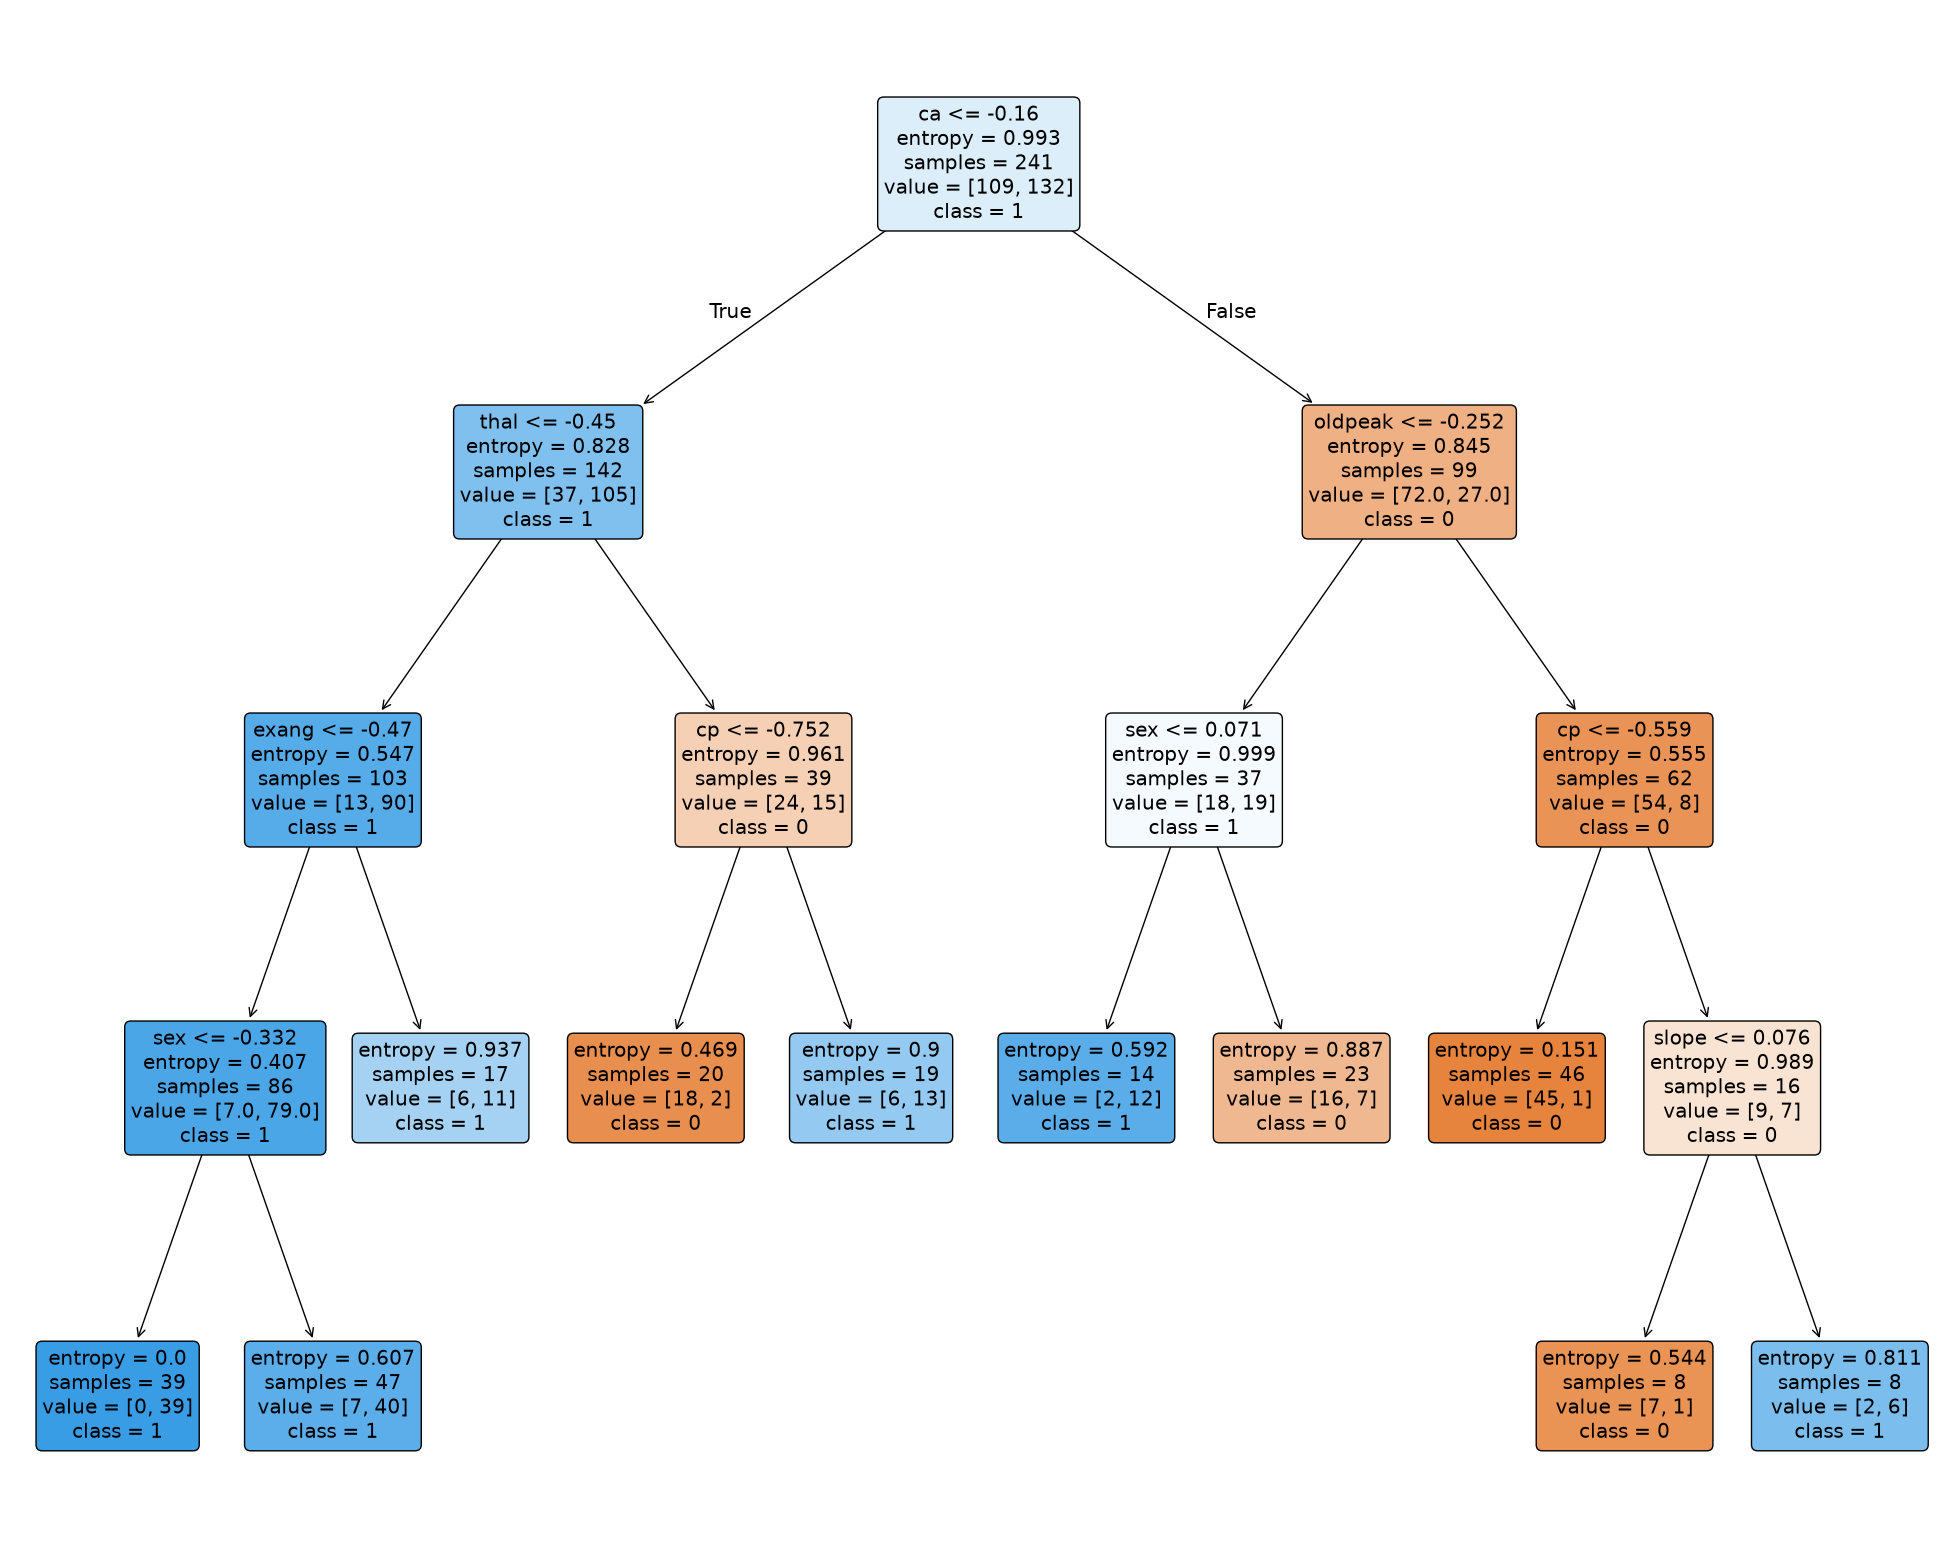

In [15]:
feature_names = df.columns[:13]

rcParams['figure.figsize'] = (25, 20)
plot_tree(dtree,
          feature_names = feature_names ,
          class_names = ['0','1'] ,
          filled = True,
          rounded = True)


## Model Comparison and Evaluation Summary

In this final section, we aggregate and compare the performance of all 4 tuned classification models:
- **Logistic Regression**
- **Gaussian Naive Bayes**
- **K-Nearest Neighbors (KNN)**
- **Decision Tree Classifier**

We evaluate **Accuracy, Precision, Recall, F1-Score, and ROC-AUC** on the held-out test set.

In [16]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
import seaborn as sns

# Dictionary of trained models
models = {
    'Logistic Regression': lr,
    'Naive Bayes': gnb,
    'K-Nearest Neighbors': knn,
    'Decision Tree': dtree
}

metrics_list = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    # Get probability estimates for ROC AUC if available
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test)[:, 1]
        auc_val = roc_auc_score(y_test, y_prob)
    else:
        auc_val = roc_auc_score(y_test, y_pred)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    metrics_list.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc_val
    })

comparison_df = pd.DataFrame(metrics_list)
comparison_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.885246,0.878788,0.90625,0.892308,0.920259
1,Naive Bayes,0.819672,0.838710,0.81250,0.825397,0.914871
2,K-Nearest Neighbors,0.803279,0.812500,0.81250,0.812500,0.859914
3,Decision Tree,0.803279,0.833333,0.78125,0.806452,0.870151


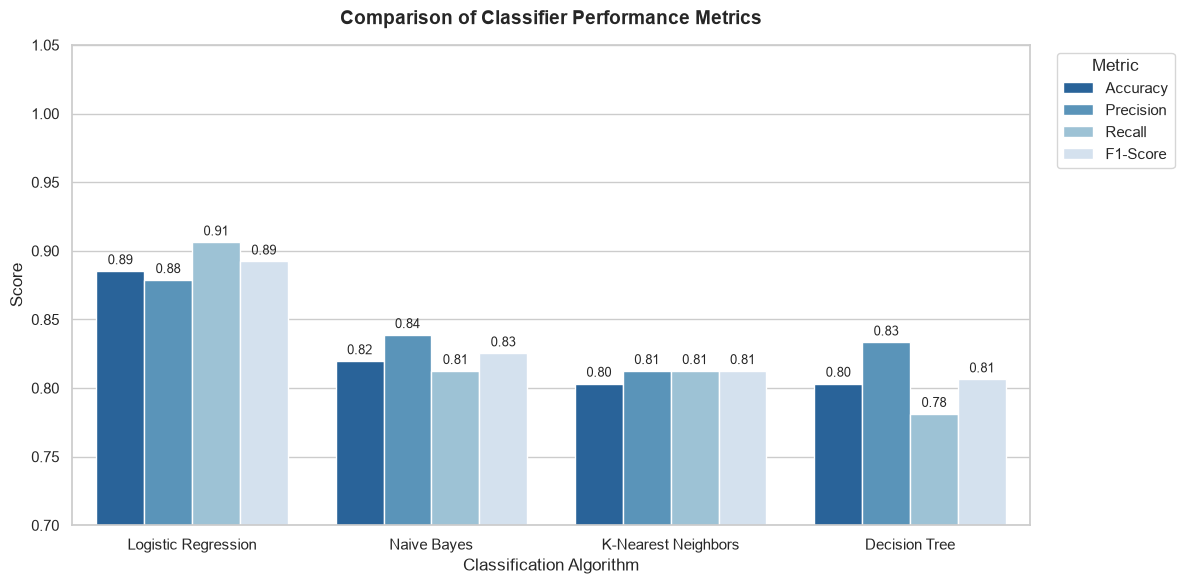

In [17]:
# Visualize comparison across models
df_melted = pd.melt(comparison_df, id_vars=['Model'],
                    value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score'],
                    var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 6))
sns.set_theme(style='whitegrid')
ax = sns.barplot(x='Model', y='Score', hue='Metric', data=df_melted, palette='Blues_r')

plt.title('Comparison of Classifier Performance Metrics', fontsize=14, fontweight='bold', pad=15)
plt.ylim(0.70, 1.05)
plt.ylabel('Score', fontsize=12)
plt.xlabel('Classification Algorithm', fontsize=12)
plt.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')

# Annotate values on top of bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.2f}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

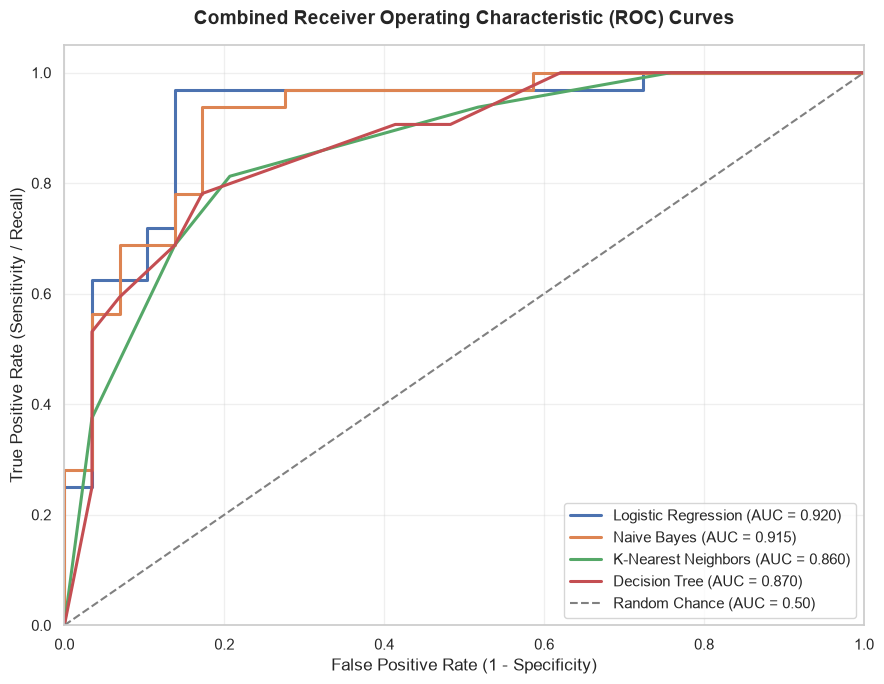

In [18]:
# Plot combined ROC Curves for all 4 models
plt.figure(figsize=(9, 7))

for name, model in models.items():
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.predict(X_test)

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2.2, label=f'{name} (AUC = {auc_score:.3f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Chance (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('Combined Receiver Operating Characteristic (ROC) Curves', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()